In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


**Cell 1: Setup and data**

In [2]:
import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import product
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.base import clone

warnings.filterwarnings("ignore")
SEED = 42
DATA_DIR = os.environ.get("DATA_DIR", ".")
FIG = "figures"
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

FEATURES = ["S1_Temp", "S2_Temp", "S3_Temp", "S4_Temp",
            "S1_Light", "S2_Light", "S3_Light", "S4_Light",
            "S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound",
            "S5_CO2", "S5_CO2_Slope", "S6_PIR", "S7_PIR"]
TARGET = "Room_Occupancy_Count"
QUANTITY = {f: ("Temp" if "Temp" in f else "Light" if "Light" in f else "Sound" if "Sound" in f
                else "PIR" if "PIR" in f else "CO2") for f in FEATURES}
CLASS_COLORS = ["#4C72B0", "#55A868", "#DD8452", "#C44E52"]

ASSETS = {"Occupancy_Estimation.csv": "occupancy-full", "train.csv": "occupancy-train", "test.csv": "occupancy-test"}
try:
    from azure.ai.ml import MLClient
    from azure.identity import DefaultAzureCredential
    ml_client = MLClient.from_config(credential=DefaultAzureCredential())
except Exception as e:
    ml_client = None
    print("No workspace connection, reading local files:", type(e).__name__)

MLFLOW = False
if ml_client is not None:
    try:
        import mlflow
        mlflow.set_tracking_uri(ml_client.workspaces.get(ml_client.workspace_name).mlflow_tracking_uri)
        mlflow.set_experiment("ee5127-g12-occupancy")
        MLFLOW = True
    except Exception as e:
        print("MLflow not available:", e)
print("Logging to Azure ML with MLflow:", MLFLOW)

def load(name):
    src = os.path.join(DATA_DIR, name)
    if ml_client is not None:
        try:
            src = ml_client.data.get(ASSETS[name], label="latest").path
        except Exception:
            pass
    d = pd.read_csv(src)
    d["ts"] = pd.to_datetime(d["Date"] + " " + d["Time"])
    print(f"{name:26s} <- {src}")
    return d

full, train, test = load("Occupancy_Estimation.csv"), load("train.csv"), load("test.csv")
X_tr, y_tr, X_te, y_te = train[FEATURES], train[TARGET], test[FEATURES], test[TARGET]
day_tr = train["Date"].values

Found the config file in: /config.json
Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented


Logging to Azure ML with MLflow: True
Occupancy_Estimation.csv   <- azureml://subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourcegroups/ro/workspaces/ml_space/datastores/workspaceblobstore/paths/UI/2026-10-27_132102_UTC/Occupancy_Estimation.csv
train.csv                  <- azureml://subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourcegroups/ro/workspaces/ml_space/datastores/workspaceblobstore/paths/UI/2026-10-27_131818_UTC/train.csv
test.csv                   <- azureml://subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourcegroups/ro/workspaces/ml_space/datastores/workspaceblobstore/paths/UI/2026-10-27_131933_UTC/test.csv


**Cell 2: dataset description**

                mean     std     min      max
S1_Temp        25.45    0.35   24.94    26.38
S2_Temp        25.55    0.59   24.75    29.00
S3_Temp        25.06    0.43   24.44    26.19
S4_Temp        25.75    0.36   24.94    26.56
S1_Light       25.45   51.01    0.00   165.00
S2_Light       26.02   67.30    0.00   258.00
S3_Light       34.25   58.40    0.00   280.00
S4_Light       13.22   19.60    0.00    74.00
S1_Sound        0.17    0.32    0.06     3.88
S2_Sound        0.12    0.27    0.04     3.44
S3_Sound        0.16    0.41    0.04     3.67
S4_Sound        0.10    0.12    0.05     3.40
S5_CO2        460.86  199.96  345.00  1270.00
S5_CO2_Slope   -0.00    1.16   -6.30     8.98
S6_PIR          0.09    0.29    0.00     1.00
S7_PIR          0.08    0.27    0.00     1.00

Rows per day and class:
 Room_Occupancy_Count     0    1    2    3
Date                                     
2017/12/22             637  205  257  363
2017/12/23            1997  254  398  130
2017/12/24            10

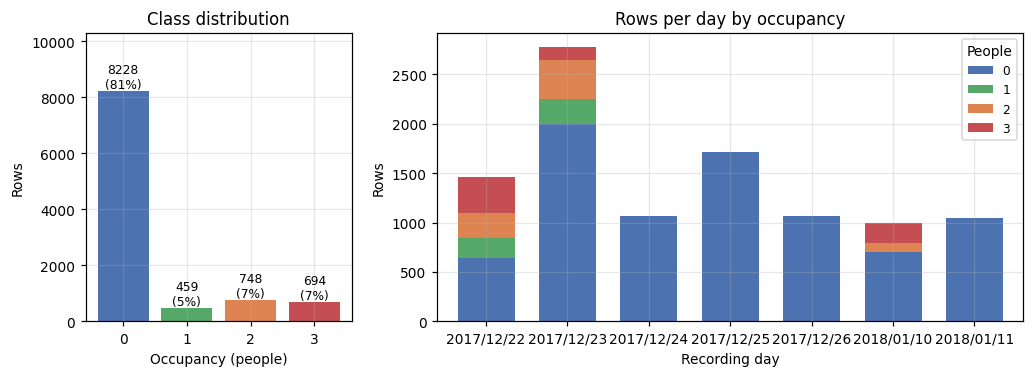

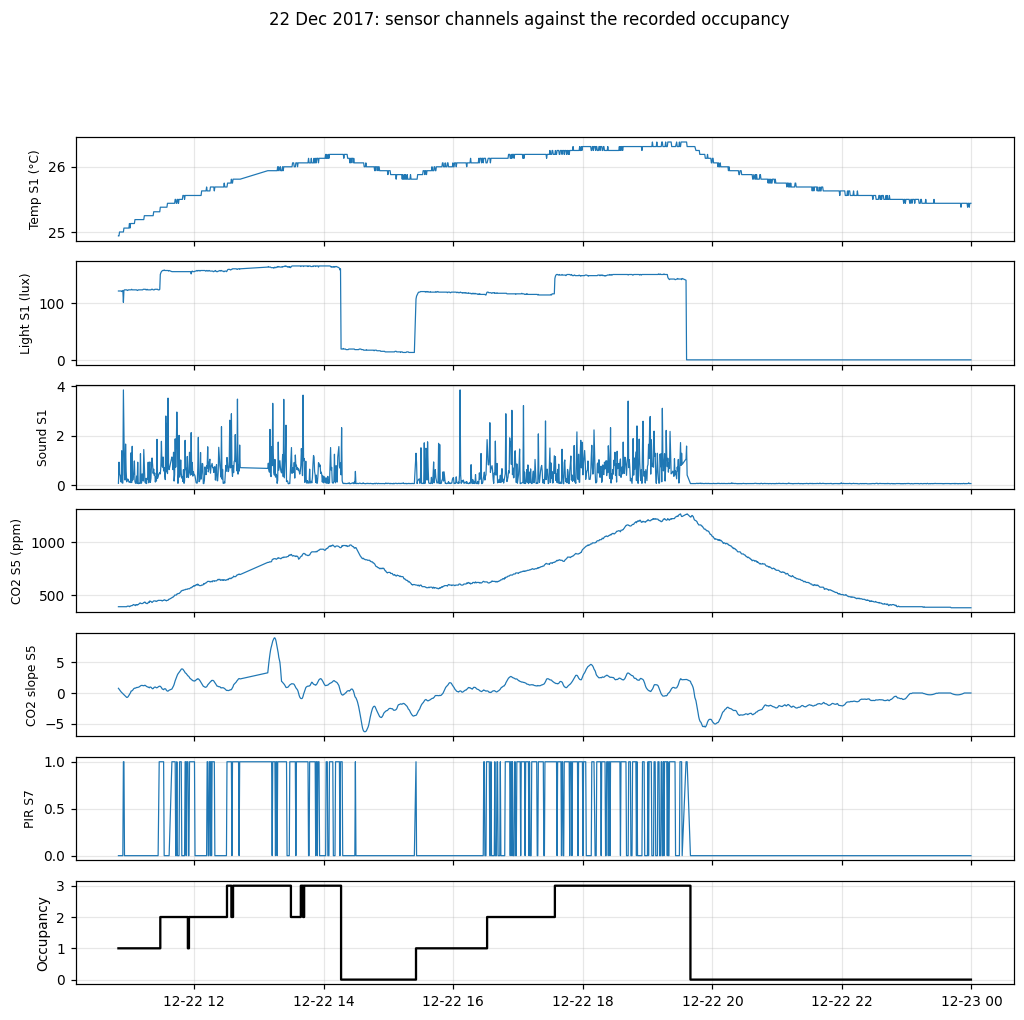

In [3]:
print(full[FEATURES].describe().T[["mean", "std", "min", "max"]].round(2))
per_day = full.groupby("Date")[TARGET].value_counts().unstack(fill_value=0)
print("\nRows per day and class:\n", per_day)
print(f"\nMedian sampling interval: {full['ts'].diff().dt.total_seconds().median():.0f} s")
print("\nTrain/test split:\n", pd.DataFrame({"train": y_tr.value_counts().sort_index(),
                                             "test": y_te.value_counts().sort_index()}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 2.2]})
vc = full[TARGET].value_counts().sort_index()
ax[0].bar(vc.index.astype(str), vc.values, color=CLASS_COLORS)
for i, v in enumerate(vc.values):
    ax[0].text(i, v, f"{v}\n({v/len(full)*100:.0f}%)", ha="center", va="bottom", fontsize=8)
ax[0].set(xlabel="Occupancy (people)", ylabel="Rows", title="Class distribution", ylim=(0, vc.max()*1.25))
per_day.plot(kind="bar", stacked=True, ax=ax[1], color=CLASS_COLORS, width=0.7)
ax[1].set(xlabel="Recording day", ylabel="Rows", title="Rows per day by occupancy")
ax[1].legend(title="People", fontsize=8); ax[1].tick_params(axis="x", rotation=0)
fig.savefig(f"{FIG}/fig01_class_balance.png"); plt.show()

day = full[full["Date"] == "2017/12/22"]
chans = [("S1_Temp", "Temp S1 (°C)"), ("S1_Light", "Light S1 (lux)"), ("S1_Sound", "Sound S1"),
         ("S5_CO2", "CO2 S5 (ppm)"), ("S5_CO2_Slope", "CO2 slope S5"), ("S7_PIR", "PIR S7")]
fig, axes = plt.subplots(len(chans) + 1, 1, figsize=(11, 10), sharex=True)
for a, (c, lab) in zip(axes, chans):
    a.plot(day["ts"], day[c], lw=0.8); a.set_ylabel(lab, fontsize=8)
axes[-1].step(day["ts"], day[TARGET], where="post", color="k")
axes[-1].set_ylabel("Occupancy"); axes[-1].set_yticks([0, 1, 2, 3])
fig.suptitle("22 Dec 2017: sensor channels against the recorded occupancy", y=0.995)
fig.savefig(f"{FIG}/fig02_timeseries_22dec.png"); plt.show()

**Cell 3: features by occupancy class**

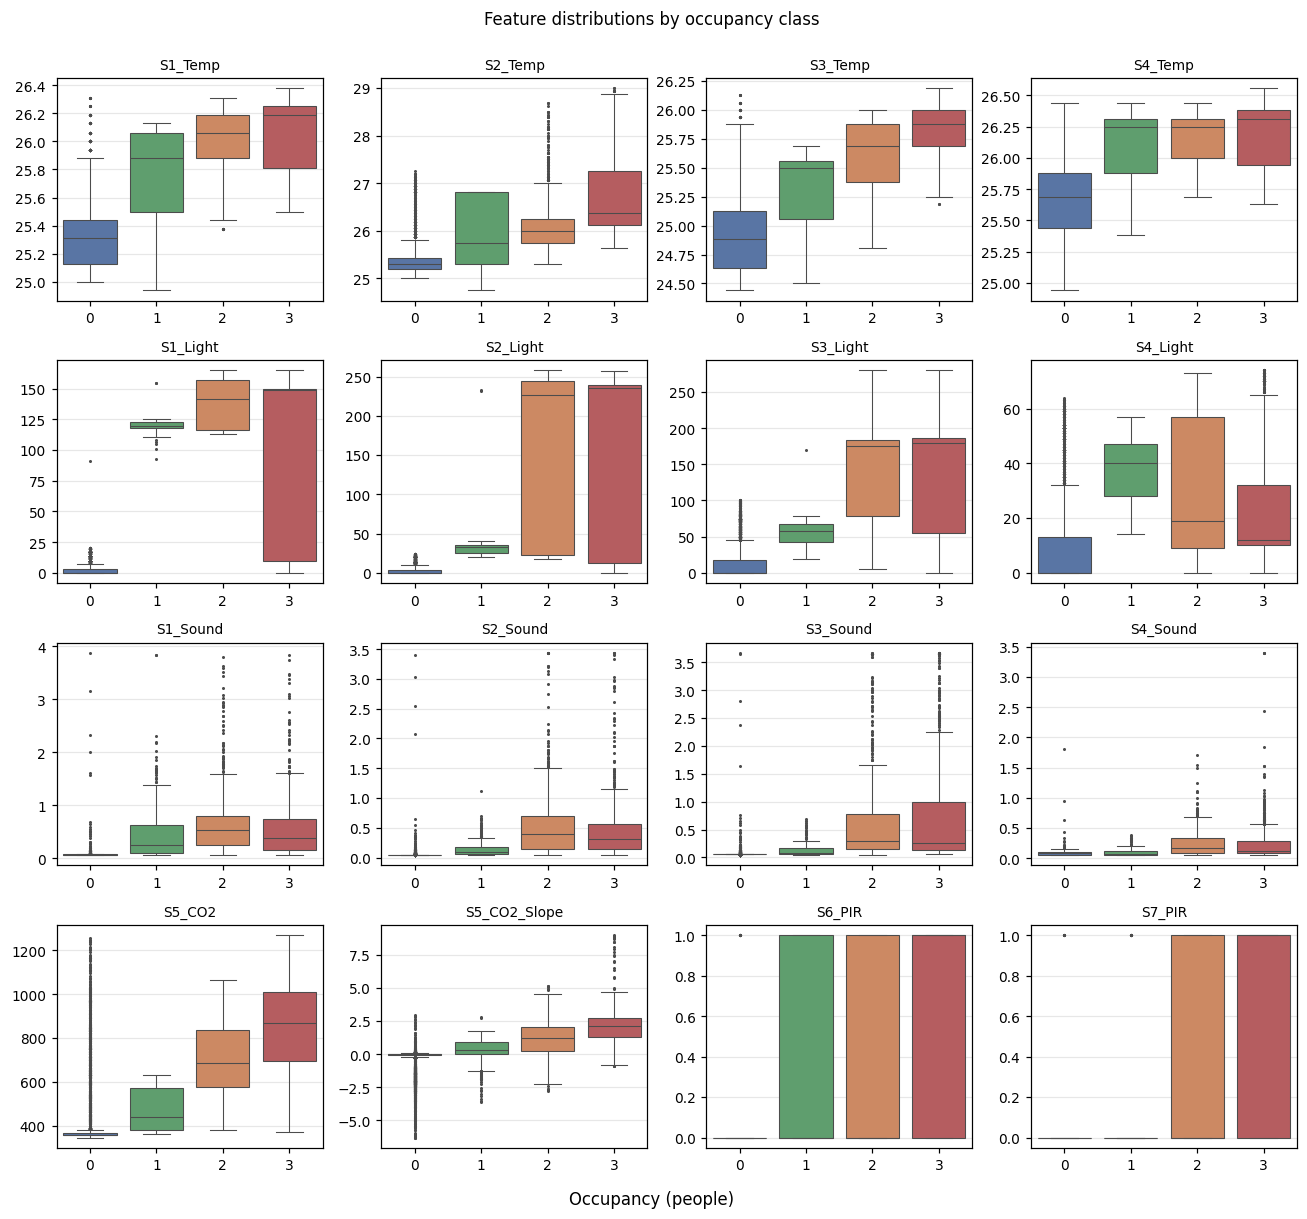

                      S6_PIR  S7_PIR
Room_Occupancy_Count                
0                      0.002   0.001
1                      0.344   0.041
2                      0.479   0.428
3                      0.543   0.656


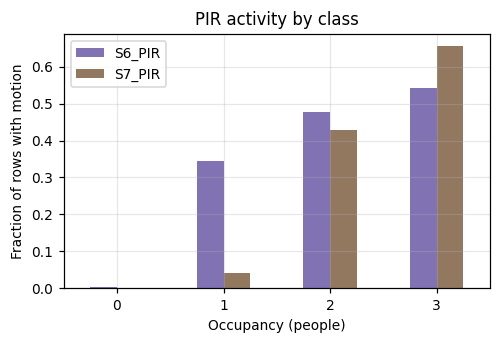

In [4]:
fig, axes = plt.subplots(4, 4, figsize=(12, 11))
for a, f in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=full, x=TARGET, y=f, ax=a, palette=CLASS_COLORS, fliersize=1, linewidth=0.7)
    a.set_title(f, fontsize=9); a.set_xlabel(""); a.set_ylabel("")
fig.supxlabel("Occupancy (people)"); fig.suptitle("Feature distributions by occupancy class", y=1.0)
fig.tight_layout(); fig.savefig(f"{FIG}/fig03_boxplots.png"); plt.show()

pir = full.groupby(TARGET)[["S6_PIR", "S7_PIR"]].mean()
print(pir.round(3))
fig, ax = plt.subplots(figsize=(5, 3))
pir.plot(kind="bar", ax=ax, color=["#8172B3", "#937860"])
ax.set(xlabel="Occupancy (people)", ylabel="Fraction of rows with motion", title="PIR activity by class")
ax.tick_params(axis="x", rotation=0)
fig.savefig(f"{FIG}/fig04_pir_by_class.png"); plt.show()

**Cell 4: how close the test rows are to training rows**

In [5]:
tr_ts = np.sort(train["ts"].values.astype("datetime64[s]").astype("int64"))
te_ts = test["ts"].values.astype("datetime64[s]").astype("int64")
pos = np.searchsorted(tr_ts, te_ts)
nearest = np.minimum(np.abs(te_ts - tr_ts[np.clip(pos - 1, 0, len(tr_ts) - 1)]),
                     np.abs(tr_ts[np.clip(pos, 0, len(tr_ts) - 1)] - te_ts))
print(f"Gap from each test row to the nearest training row: median {np.median(nearest):.0f} s, "
      f"{(nearest <= 35).mean()*100:.1f}% within 35 s, max {nearest.max():.0f} s")


from sklearn.dummy import DummyClassifier
p = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr).predict(X_te)
print(f"Always-0 baseline on the held-out test portion: "
      f"accuracy {accuracy_score(y_te, p):.3f}, macro-F1 {f1_score(y_te, p, average='macro'):.3f}")

Gap from each test row to the nearest training row: median 30 s, 95.7% within 35 s, max 92 s
Always-0 baseline on the held-out test portion: accuracy 0.812, macro-F1 0.224


**Cell 5: model comparison**

🏃 View run compare Logistic regression at: https://swedencentral.api.azureml.ms/mlflow/v2.0/subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourceGroups/ro/providers/Microsoft.MachineLearningServices/workspaces/ml_space/#/experiments/85fc73d6-e3f9-4f19-b696-f5f156452d80/runs/d6c74995-aab5-41af-bbe8-78a4c4b2c583
🧪 View experiment at: https://swedencentral.api.azureml.ms/mlflow/v2.0/subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourceGroups/ro/providers/Microsoft.MachineLearningServices/workspaces/ml_space/#/experiments/85fc73d6-e3f9-4f19-b696-f5f156452d80
🏃 View run compare Decision tree at: https://swedencentral.api.azureml.ms/mlflow/v2.0/subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourceGroups/ro/providers/Microsoft.MachineLearningServices/workspaces/ml_space/#/experiments/85fc73d6-e3f9-4f19-b696-f5f156452d80/runs/1aca95df-300c-4e62-99f0-6851438e8882
🧪 View experiment at: https://swedencentral.api.azureml.ms/mlflow/v2.0/subscriptions/6c905e17-5c6f-4308-bf14-f00bc6

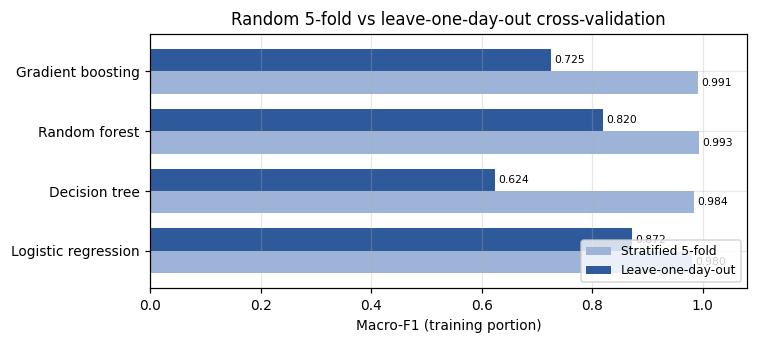


Macro-F1 on each occupied day when that day is held out:
            Logistic regression  Decision tree  Random forest  Gradient boosting
2017/12/22                0.888          0.770          0.839              0.732
2017/12/23                0.950          0.483          0.865              0.804
2018/01/10                0.539          0.504          0.499              0.328


In [6]:
MODELS = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Decision tree":       DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=SEED),
    "Random forest":       RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "Gradient boosting":   HistGradientBoostingClassifier(max_iter=200, random_state=SEED),
}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
logo = LeaveOneGroupOut()

def cv_eval(model, X, scheme):
    if scheme == "kfold":
        return cross_val_predict(model, X, y_tr, cv=skf)
    return cross_val_predict(model, X, y_tr, cv=logo, groups=day_tr)

rows, lodo_preds = [], {}
for name, m in MODELS.items():
    r = {"model": name}
    for scheme in ["kfold", "lodo"]:
        p = cv_eval(m, X_tr, scheme)
        r[f"macro_f1_{scheme}"] = round(f1_score(y_tr, p, average="macro"), 4)
        r[f"accuracy_{scheme}"] = round(accuracy_score(y_tr, p), 4)
        if scheme == "lodo":
            lodo_preds[name] = p
    rows.append(r)
    if MLFLOW:
        with mlflow.start_run(run_name=f"compare {name}"):
            mlflow.log_param("model", name)
            mlflow.log_metrics({k: v for k, v in r.items() if k != "model"})
cv_tab = pd.DataFrame(rows).set_index("model")
print(cv_tab.to_string())

fig, ax = plt.subplots(figsize=(7, 3))
cv_tab[["macro_f1_kfold", "macro_f1_lodo"]].plot(kind="barh", ax=ax, color=["#9DB4D8", "#2E5A9C"], width=0.75)
ax.set(xlabel="Macro-F1 (training portion)", ylabel="", xlim=(0, 1.08),
       title="Random 5-fold vs leave-one-day-out cross-validation")
ax.legend(["Stratified 5-fold", "Leave-one-day-out"], loc="lower right", fontsize=8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2)
fig.savefig(f"{FIG}/fig05_model_comparison.png"); plt.show()

occupied_days = ["2017/12/22", "2017/12/23", "2018/01/10"]
print("\nMacro-F1 on each occupied day when that day is held out:")
print(pd.DataFrame({name: {d: round(f1_score(y_tr[day_tr == d], p[day_tr == d], average="macro",
                                             labels=sorted(set(y_tr[day_tr == d]))), 3)
                           for d in occupied_days} for name, p in lodo_preds.items()}).to_string())

**Cell 6: sensor subsets and data budget**

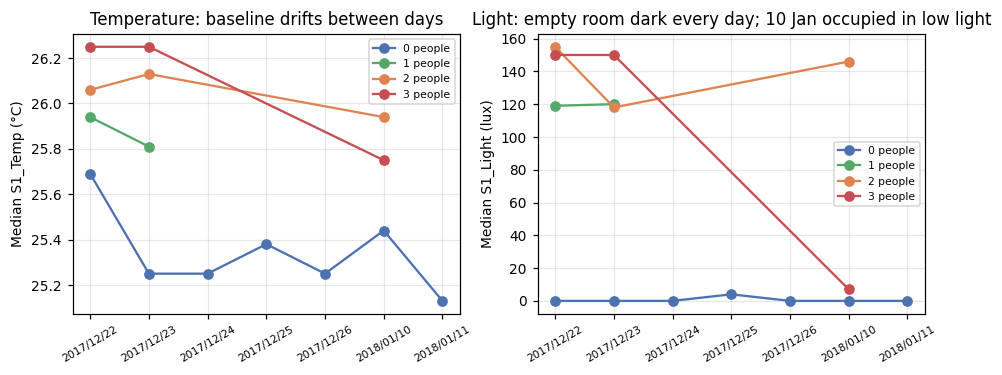

                            n_features  nodes  rf_lodo_f1  lr_lodo_f1  ble_bytes  json_bytes  iothub_msgs_per_day
subset                                                                                                           
All 16 features                     16      7      0.8046      0.8717         68         315                 2880
No temperature                      12      7      0.8598      0.8522         52         251                 1440
No sound                            12      7      0.8238      0.8751         52         251                 1440
No CO2 (no S5 node)                 14      6      0.8144      0.8571         60         279                 2880
No PIR (no S6/S7 nodes)             14      5      0.7873      0.8682         60         289                 2880
No light                            12      7      0.4235      0.5298         52         250                 1440
Light + sound (S1–S4 only)           8      4      0.8461      0.8498         36        

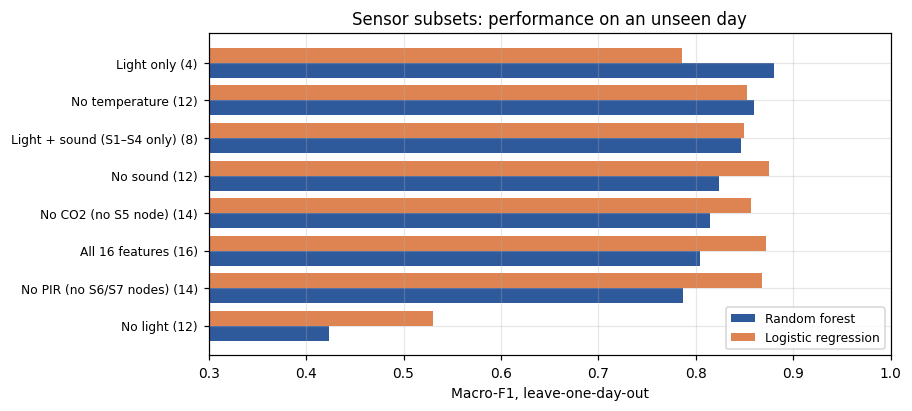

window 10 samples: r = 0.7891, max difference = 8.4582
window 20 samples: r = 0.9779, max difference = 4.0110
window 24 samples: r = 0.9991, max difference = 1.0590
window 25 samples: r = 1.0000, max difference = 0.0000
window 26 samples: r = 0.9992, max difference = 0.6427
window 30 samples: r = 0.9876, max difference = 2.3958


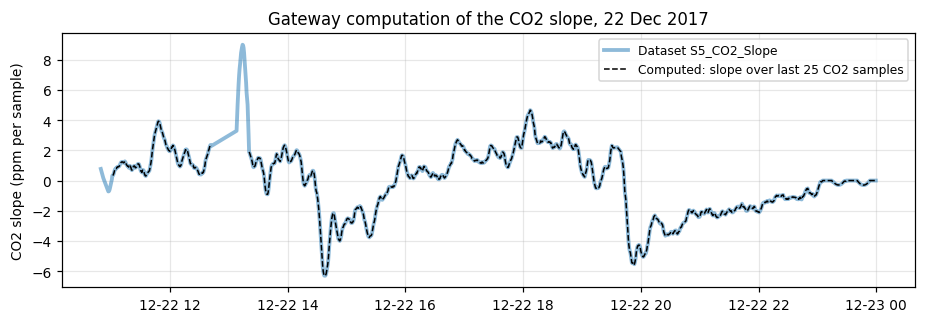

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for k in range(4):
    for a, col in zip(ax, ["S1_Temp", "S1_Light"]):
        s = full[full[TARGET] == k].groupby("Date")[col].median()
        a.plot(s.index, s.values, "o-", color=CLASS_COLORS[k], label=f"{k} people")
ax[0].set(ylabel="Median S1_Temp (°C)", title="Temperature: baseline drifts between days")
ax[1].set(ylabel="Median S1_Light (lux)", title="Light: empty room dark every day; 10 Jan occupied in low light")
for a in ax:
    a.tick_params(axis="x", rotation=30, labelsize=7); a.legend(fontsize=7)
fig.savefig(f"{FIG}/fig06_daily_drift.png"); plt.show()

Q = lambda q: [f for f in FEATURES if QUANTITY[f] == q]
SUBSETS = {
    "All 16 features":            FEATURES,
    "No temperature":             Q("Light") + Q("Sound") + Q("CO2") + Q("PIR"),
    "No sound":                   Q("Light") + Q("Temp") + Q("CO2") + Q("PIR"),
    "No CO2 (no S5 node)":        Q("Light") + Q("Sound") + Q("Temp") + Q("PIR"),
    "No PIR (no S6/S7 nodes)":    Q("Light") + Q("Sound") + Q("Temp") + Q("CO2"),
    "No light":                   Q("Temp") + Q("Sound") + Q("CO2") + Q("PIR"),
    "Light + sound (S1–S4 only)": Q("Light") + Q("Sound"),
    "Light only":                 Q("Light"),
}
BASE = RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=SEED)

def json_bytes(cols):
    body = {"sample_id": 123456, "receivedAt": "2026-11-10T12:00:00.000Z",
            **{c: round(float(train[c].iloc[0]), 3) for c in cols}}
    return len(json.dumps(body, separators=(",", ":")))

rows = []
for name, cols in SUBSETS.items():
    b = json_bytes(cols)
    rows.append({"subset": name, "n_features": len(cols),
                 "nodes": len({c.split("_")[0] for c in cols}),
                 "rf_lodo_f1": round(f1_score(y_tr, cv_eval(BASE, X_tr[cols], "lodo"), average="macro"), 4),
                 "lr_lodo_f1": round(f1_score(y_tr, cv_eval(MODELS["Logistic regression"], X_tr[cols], "lodo"), average="macro"), 4),
                 "ble_bytes": 4 + 4 * len(cols), "json_bytes": b,
                 "iothub_msgs_per_day": int(np.ceil(2880 / max(1, 512 // b)))})
abl = pd.DataFrame(rows).set_index("subset")
print(abl.to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
a2 = abl.sort_values("rf_lodo_f1")
yy = np.arange(len(a2))
ax.barh(yy - 0.2, a2["rf_lodo_f1"], 0.4, label="Random forest", color="#2E5A9C")
ax.barh(yy + 0.2, a2["lr_lodo_f1"], 0.4, label="Logistic regression", color="#DD8452")
ax.set_yticks(yy); ax.set_yticklabels([f"{s} ({n})" for s, n in zip(a2.index, a2["n_features"])], fontsize=8)
ax.set(xlabel="Macro-F1, leave-one-day-out", xlim=(0.3, 1), title="Sensor subsets: performance on an unseen day")
ax.legend(fontsize=8, loc="lower right")
fig.savefig(f"{FIG}/fig07_sensor_subsets.png"); plt.show()

def slope(x):
    t = np.arange(len(x)) - (len(x) - 1) / 2
    return (t * (x - x.mean())).sum() / (t * t).sum()

segment = (full["ts"].diff().dt.total_seconds() > 300).cumsum()
for N in [10, 20, 24, 25, 26, 30]:
    s = full.groupby(segment)["S5_CO2"].transform(lambda x: x.rolling(N).apply(slope, raw=True))
    ok = s.notna()
    print(f"window {N:2d} samples: r = {np.corrcoef(s[ok], full.loc[ok, 'S5_CO2_Slope'])[0, 1]:.4f}, "
          f"max difference = {np.abs(s[ok] - full.loc[ok, 'S5_CO2_Slope']).max():.4f}")

gw = full.groupby(segment)["S5_CO2"].transform(lambda x: x.rolling(25).apply(slope, raw=True))
day = full["Date"] == "2017/12/22"
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(full.loc[day, "ts"], full.loc[day, "S5_CO2_Slope"], lw=2.5, alpha=0.5, label="Dataset S5_CO2_Slope")
ax.plot(full.loc[day, "ts"], gw[day], "--", lw=1, color="k", label="Computed: slope over last 25 CO2 samples")
ax.set(ylabel="CO2 slope (ppm per sample)", title="Gateway computation of the CO2 slope, 22 Dec 2017")
ax.legend(fontsize=8)
fig.savefig(f"{FIG}/fig10_co2_slope_gateway.png"); plt.show()

**Cell 7: tune the candidates, test once, choose the model**

🏃 View run tuned RF – all 16 at: https://swedencentral.api.azureml.ms/mlflow/v2.0/subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourceGroups/ro/providers/Microsoft.MachineLearningServices/workspaces/ml_space/#/experiments/85fc73d6-e3f9-4f19-b696-f5f156452d80/runs/7349a904-eec6-4088-b67c-b24bd9a484d2
🧪 View experiment at: https://swedencentral.api.azureml.ms/mlflow/v2.0/subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourceGroups/ro/providers/Microsoft.MachineLearningServices/workspaces/ml_space/#/experiments/85fc73d6-e3f9-4f19-b696-f5f156452d80
🏃 View run tuned LR – all 16 at: https://swedencentral.api.azureml.ms/mlflow/v2.0/subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourceGroups/ro/providers/Microsoft.MachineLearningServices/workspaces/ml_space/#/experiments/85fc73d6-e3f9-4f19-b696-f5f156452d80/runs/b3337255-d1c4-49af-b0de-1ef5a7d9de0b
🧪 View experiment at: https://swedencentral.api.azureml.ms/mlflow/v2.0/subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourc

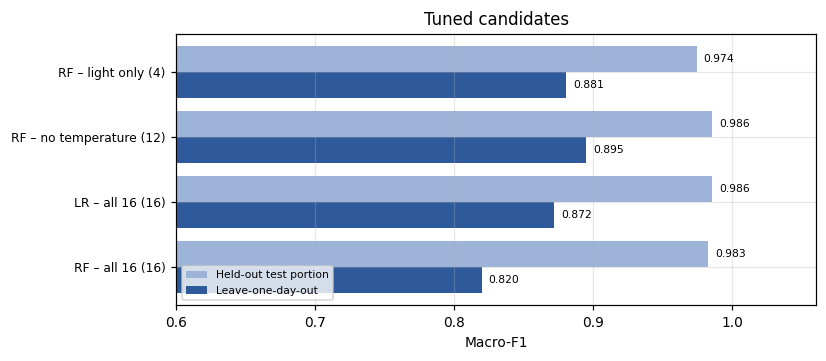

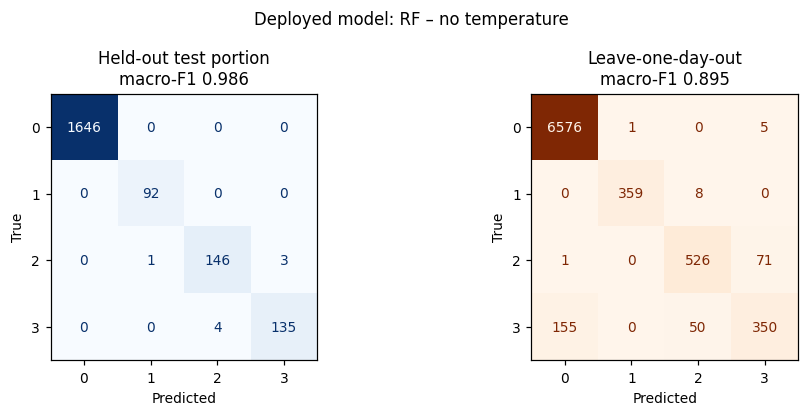

In [8]:
from itertools import product

FINAL = {
    "RF – all 16":         ("rf", FEATURES),
    "LR – all 16":         ("lr", FEATURES),
    "RF – no temperature": ("rf", SUBSETS["No temperature"]),
    "RF – light only":     ("rf", SUBSETS["Light only"]),
}
GRIDS = {"rf": {"max_depth": [None, 8], "min_samples_leaf": [1, 5]},
         "lr": {"logisticregression__C": [0.01, 0.1, 1, 10]}}

def tune(kind, cols):
    base = (RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEED)
            if kind == "rf" else MODELS["Logistic regression"])
    best = None
    for combo in product(*GRIDS[kind].values()):
        params = dict(zip(GRIDS[kind], combo))
        p = cv_eval(clone(base).set_params(**params), X_tr[cols], "lodo")
        s = f1_score(y_tr, p, average="macro")
        if best is None or s > best[0]:
            best = (s, params, p)
    return clone(base).set_params(**best[1]), best

rows, final_models = [], {}
for name, (kind, cols) in FINAL.items():
    model, (lodo_f1, params, p_lodo) = tune(kind, cols)
    model.fit(X_tr[cols], y_tr)
    p = model.predict(X_te[cols])
    final_models[name] = (model, cols, params, p, p_lodo)
    rows.append({"candidate": name, "n_features": len(cols), "params": params,
                 "lodo_macro_f1": round(lodo_f1, 4),
                 "test_macro_f1": round(f1_score(y_te, p, average="macro"), 4),
                 "test_accuracy": round(accuracy_score(y_te, p), 4)})
    if MLFLOW:
        with mlflow.start_run(run_name=f"tuned {name}"):
            mlflow.log_params({"candidate": name, "features": ",".join(cols), **params})
            mlflow.log_metrics({k: v for k, v in rows[-1].items() if k.endswith(("f1", "accuracy"))})
final_tab = pd.DataFrame(rows).set_index("candidate")
print(final_tab.to_string())

best = final_tab["lodo_macro_f1"].max()
DEPLOY = (final_tab[final_tab["lodo_macro_f1"] >= best - 0.01]
          .sort_values(["n_features", "lodo_macro_f1"], ascending=[True, False]).index[0])
model, cols, params, p_test, p_lodo = final_models[DEPLOY]
print(f"\nModel to deploy: {DEPLOY} {params}\n")
print(classification_report(y_te, p_test, digits=3))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
yy = np.arange(len(final_tab))
ax.barh(yy + 0.2, final_tab["test_macro_f1"], 0.4, label="Held-out test portion", color="#9DB4D8")
ax.barh(yy - 0.2, final_tab["lodo_macro_f1"], 0.4, label="Leave-one-day-out", color="#2E5A9C")
for y_, a, b in zip(yy, final_tab["test_macro_f1"], final_tab["lodo_macro_f1"]):
    ax.text(a + 0.005, y_ + 0.2, f"{a:.3f}", va="center", fontsize=7)
    ax.text(b + 0.005, y_ - 0.2, f"{b:.3f}", va="center", fontsize=7)
ax.set_yticks(yy); ax.set_yticklabels([f"{c} ({n})" for c, n in zip(final_tab.index, final_tab["n_features"])], fontsize=8)
ax.set(xlabel="Macro-F1", xlim=(0.6, 1.06), title="Tuned candidates")
ax.legend(fontsize=7, loc="lower left")
fig.savefig(f"{FIG}/fig08_final_candidates.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for a, (yt, yp, lab, cmap) in zip(axes, [(y_te, p_test, "Held-out test portion", "Blues"),
                                         (y_tr, p_lodo, "Leave-one-day-out", "Oranges")]):
    ConfusionMatrixDisplay(confusion_matrix(yt, yp, labels=[0, 1, 2, 3]), display_labels=[0, 1, 2, 3]).plot(
        ax=a, cmap=cmap, colorbar=False)
    a.set(title=f"{lab}\nmacro-F1 {f1_score(yt, yp, average='macro'):.3f}", xlabel="Predicted", ylabel="True")
    a.grid(False)
fig.suptitle(f"Deployed model: {DEPLOY}")
fig.tight_layout(); fig.savefig(f"{FIG}/fig09_confusion_deployed.png"); plt.show()

**Cell 8: save and register the model**

In [9]:
import joblib, shutil
from mlflow.models import infer_signature
import mlflow.sklearn
from azure.ai.ml.entities import Model
from azure.ai.ml.constants import AssetTypes

os.makedirs("model", exist_ok=True)
joblib.dump(model, "model/occupancy_model.joblib")
json.dump({"candidate": DEPLOY, "features_in_order": cols, "params": params, "classes": [0, 1, 2, 3]},
          open("model/deploy_config.json", "w"), indent=2)
assert (joblib.load("model/occupancy_model.joblib").predict(X_te[cols]) == p_test).all()
print("Saved model/occupancy_model.joblib and model/deploy_config.json")

shutil.rmtree("model/mlflow_model", ignore_errors=True)
mlflow.sklearn.save_model(model, "model/mlflow_model",
                          signature=infer_signature(X_tr[cols], model.predict(X_tr[cols])),
                          input_example=X_tr[cols].head(2))

registered = ml_client.models.create_or_update(Model(
    path="model/mlflow_model", type=AssetTypes.MLFLOW_MODEL, name="ee5127-g12-occupancy",
    description=f"{DEPLOY}, features: {', '.join(cols)}"))
print(f"Registered '{registered.name}' version {registered.version}")

if MLFLOW:
    with mlflow.start_run(run_name=f"DEPLOY {DEPLOY}"):
        mlflow.log_params({"candidate": DEPLOY, "features": ",".join(cols), **params})
        mlflow.log_metrics(final_tab.loc[DEPLOY, ["lodo_macro_f1", "test_macro_f1", "test_accuracy"]].astype(float).to_dict())
        mlflow.set_tag("registered_model", f"{registered.name}:{registered.version}")

Saved model/occupancy_model.joblib and model/deploy_config.json
Registered 'ee5127-g12-occupancy' version 2
🏃 View run DEPLOY RF – no temperature at: https://swedencentral.api.azureml.ms/mlflow/v2.0/subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourceGroups/ro/providers/Microsoft.MachineLearningServices/workspaces/ml_space/#/experiments/85fc73d6-e3f9-4f19-b696-f5f156452d80/runs/a3c0bb82-fb51-4d1f-b4bd-24dfb0572623
🧪 View experiment at: https://swedencentral.api.azureml.ms/mlflow/v2.0/subscriptions/6c905e17-5c6f-4308-bf14-f00bc6225a53/resourceGroups/ro/providers/Microsoft.MachineLearningServices/workspaces/ml_space/#/experiments/85fc73d6-e3f9-4f19-b696-f5f156452d80


Uploading mlflow_model (5.47 MBs): 100%|██████████| 5465578/5465578 [00:00<00:00, 85693175.99it/s]




In [10]:
   import mlflow.pyfunc
   m = mlflow.pyfunc.load_model("model/mlflow_model")
   print(m.predict(X_te[cols].head(5)), y_te.head(5).values)

[1 1 1 1 1] [1 1 1 1 1]


In [ ]:
import zipfile, glob
with zipfile.ZipFile("d2_project.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for path in glob.glob("figures/**", recursive=True) + glob.glob("model/**", recursive=True) + glob.glob("*.ipynb"):
        z.write(path)
print("Created d2_project.zip")